In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/AB_NYC_2019.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Target variable: price

Missing prices:
0

Zero-price listings:
11

Price statistics:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

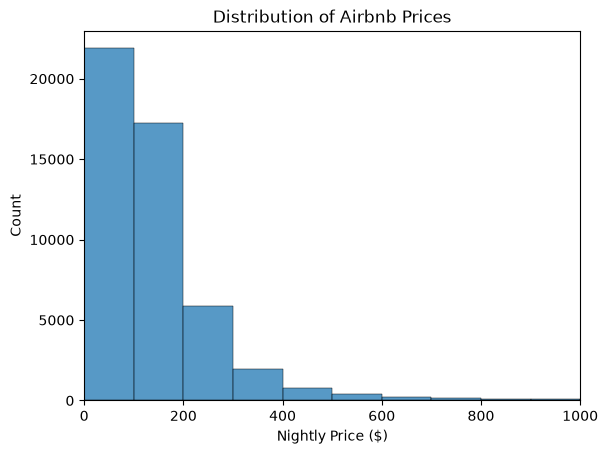

In [17]:
print("Target variable: price")

print("\nMissing prices:")
print(df["price"].isnull().sum())

print("\nZero-price listings:")
print((df["price"] == 0).sum())

print("\nPrice statistics:")
display(df["price"].describe())

sns.histplot(data=df, x="price", bins=100)
plt.xlim(0, 1000)
plt.title("Distribution of Airbnb Prices")
plt.xlabel("Nightly Price ($)")
plt.show()

# 2. Data Preparation

In [18]:
# Check missing values
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

# Check invalid prices
print("Zero-price listings:", (df["price"] == 0).sum())
print("Negative-price listings:", (df["price"] < 0).sum())

# Check target distribution
print("Price skewness:", df["price"].skew())

Missing values:


last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
neighbourhood_group                   0
neighbourhood                         0
id                                    0
host_id                               0
longitude                             0
latitude                              0
room_type                             0
price                                 0
number_of_reviews                     0
minimum_nights                        0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Zero-price listings: 11
Negative-price listings: 0
Price skewness: 19.118938995046033


In [19]:
features = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

target = "price"

X = df[features].copy()
y = df[target].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (48895, 10)
Target shape: (48895,)


,neighbourhood_group,neighbourhood,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,Private room,40.64749,-73.97237,1,9,0.21,6,365
1,Manhattan,Midtown,Entire home/apt,40.75362,-73.98377,1,45,0.38,2,355
2,Manhattan,Harlem,Private room,40.80902,-73.94190,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,Entire home/apt,40.68514,-73.95976,1,270,4.64,1,194
4,Manhattan,East Harlem,Entire home/apt,40.79851,-73.94399,10,9,0.10,1,0


# 3. Clean the data

In [20]:
# Create a working dataset
model_df = df[features + [target]].copy()

# Remove listings with invalid target prices
model_df = model_df[model_df["price"] > 0].copy()

# Fill missing numerical values using medians
numeric_cols = model_df.select_dtypes(include=np.number).columns.drop("price")

for col in numeric_cols:
    model_df[col] = model_df[col].fillna(model_df[col].median())

# Fill missing categorical values
categorical_cols = model_df.select_dtypes(include="object").columns

for col in categorical_cols:
    model_df[col] = model_df[col].fillna("Unknown")

print("Original rows:", len(df))
print("Rows after cleaning:", len(model_df))
print("\nRemaining missing values:", model_df.isnull().sum().sum())
print("Remaining zero/negative prices:", (model_df["price"] <= 0).sum())

Original rows: 48895
Rows after cleaning: 48884

Remaining missing values: 0
Remaining zero/negative prices: 0


C:\Users\awara\AppData\Local\Temp\ipykernel_40248\2209553376.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = model_df.select_dtypes(include="object").columns


# 4. Train-Test split

In [21]:


X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (39107, 10)
Testing features: (9777, 10)
Training target: (39107,)
Testing target: (9777,)


In [22]:


# Separate numerical and categorical features
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Preprocess numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [23]:
linear_model.fit(X_train, y_train)

print("Linear Regression training complete!")

Linear Regression training complete!


In [24]:

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"R²:    {r2:.4f}")

MAE:  $70.70
RMSE: $186.05
R²:    0.1354


In [25]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [26]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"MAE:  ${rf_mae:.2f}")
print(f"RMSE: ${rf_rmse:.2f}")
print(f"R²:    {rf_r2:.4f}")

MAE:  $64.77
RMSE: $182.71
R²:    0.1662


In [27]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,70.699,186.046,0.135
1,Random Forest,64.765,182.706,0.166


In [28]:
# Get feature names after preprocessing
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance scores
importances = rf_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

,Feature,Importance
1,num__longitude,0.193369
0,num__latitude,0.168666
6,num__availability_365,0.104675
2,num__minimum_nights,0.103082
230,cat__room_type_Entire home/apt,0.090601
5,num__calculated_host_listings_count,0.067893
4,num__reviews_per_month,0.064461
3,num__number_of_reviews,0.046240
18,cat__neighbourhood_Battery Park City,0.019773
16,cat__neighbourhood_Astoria,0.016560


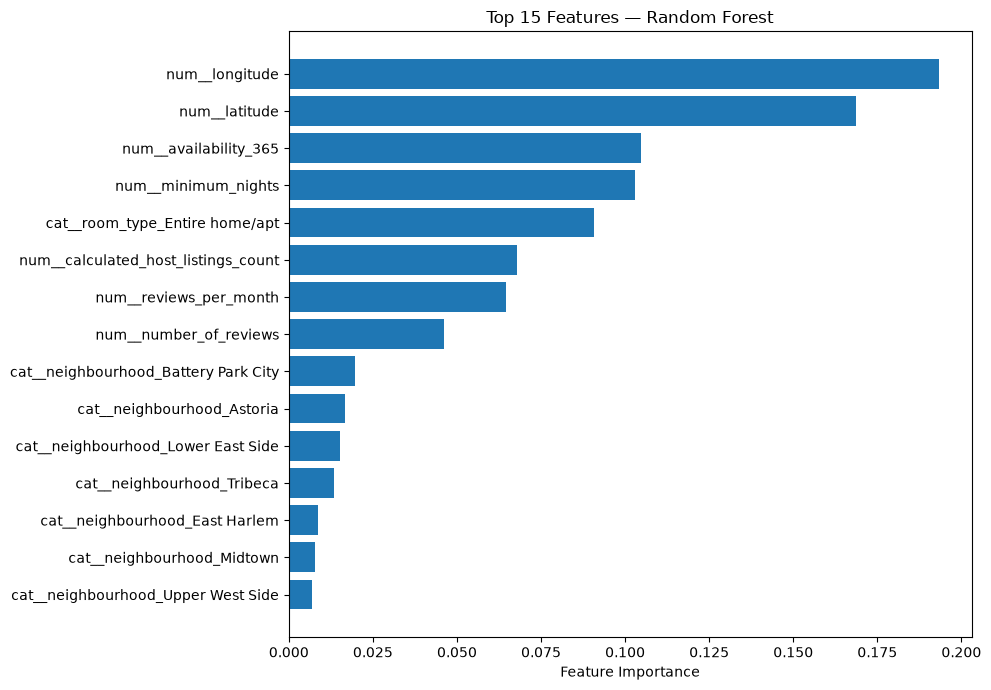

In [29]:
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features — Random Forest")
plt.tight_layout()
plt.show()

In [30]:
from sklearn.base import clone

rf_log_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using log-transformed prices
rf_log_model.fit(X_train, np.log1p(y_train))

# Predict and convert back to dollars
log_predictions = rf_log_model.predict(X_test)
rf_log_pred = np.maximum(0, np.expm1(log_predictions))

# Evaluate on the original dollar scale
log_mae = mean_absolute_error(y_test, rf_log_pred)
log_rmse = np.sqrt(mean_squared_error(y_test, rf_log_pred))
log_r2 = r2_score(y_test, rf_log_pred)

print(f"Log model MAE:  ${log_mae:.2f}")
print(f"Log model RMSE: ${log_rmse:.2f}")
print(f"Log model R²:   {log_r2:.4f}")

Log model MAE:  $55.63
Log model RMSE: $177.25
Log model R²:   0.2152


In [31]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Random Forest (Log Target)"
    ],
    "MAE": [mae, rf_mae, log_mae],
    "RMSE": [rmse, rf_rmse, log_rmse],
    "R2": [r2, rf_r2, log_r2]
})

display(comparison.round(3).sort_values("MAE"))

,Model,MAE,RMSE,R2
2,Random Forest (Log Target),55.629,177.253,0.215
1,Random Forest,64.765,182.706,0.166
0,Linear Regression,70.699,186.046,0.135


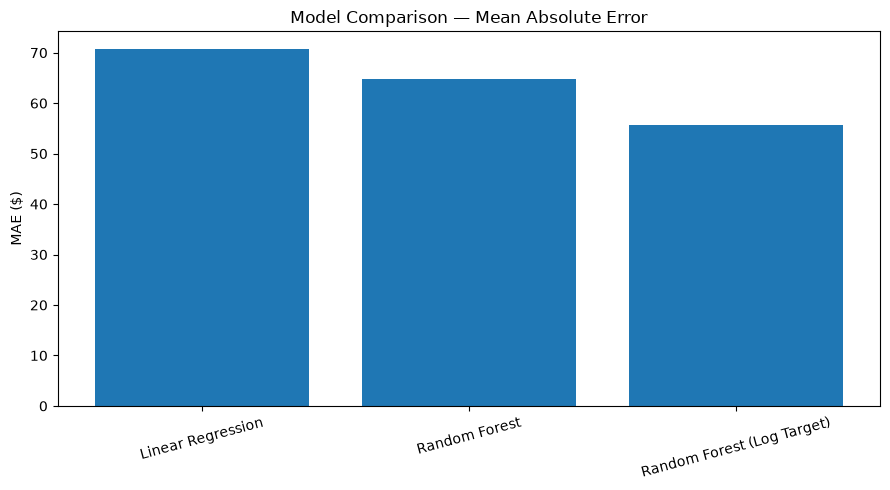

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(comparison["Model"], comparison["MAE"])

plt.title("Model Comparison — Mean Absolute Error")
plt.ylabel("MAE ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [34]:
import joblib
from pathlib import Path

model_path = Path("../models/airbnb_price_model.pkl")
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(rf_log_model, model_path)

print("Model saved successfully!")

Model saved successfully!


In [35]:
import joblib
import numpy as np
from pathlib import Path

model_path = Path("../models/airbnb_price_model.pkl")

loaded_model = joblib.load(model_path)

# Predict using one unseen test sample
sample = X_test.iloc[[0]]

log_prediction = loaded_model.predict(sample)
predicted_price = np.expm1(log_prediction[0])

print(f"Predicted Airbnb price: ${predicted_price:.2f}")
print(f"Actual Airbnb price:   ${y_test.iloc[0]:.2f}")

Predicted Airbnb price: $95.04
Actual Airbnb price:   $99.00
